In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
df = pd.read_csv("D:/ecomai/data/processed/cleaned_ecommerce_data.csv")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


#snapshot date
snapshot_date = df['InvoiceDate'].max()+pd.Timedelta(days=1)


In [2]:
print(df['Revenue'].describe())

count    397884.000000
mean         22.397000
std         309.071041
min           0.001000
25%           4.680000
50%          11.800000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64


In [6]:

snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Create RFM DataFrame
rfm = (
    df.groupby('CustomerID')
      .agg(
          Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
          Frequency=('InvoiceNo', 'nunique'),
          Monetary=('TotalPrice', 'sum')
      )
      .reset_index()
)

# Calculate R, F, M Scores
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

In [7]:
# 1. Map scores into human-readable customer segments
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New / Recent Customers'
    elif r == 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 4:
        return 'At Risk / Can\'t Lose'
    elif r <= 2 and f <= 2:
        return 'Lost Customers'
    else:
        return 'Needs Attention'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# 2. Inspect segment breakdown
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).reset_index().sort_values(by='Customer_Count', ascending=False)

display(segment_summary)

,Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
1,Champions,1139,13.311677,9.986831,5204.323012
2,Lost Customers,1065,217.897653,1.101408,487.707579
3,Loyal Customers,821,38.043849,3.643118,1651.333386
4,Needs Attention,368,164.627717,2.293478,998.083046
6,Potential Loyalists,351,53.504274,1.162393,461.061510
5,New / Recent Customers,319,18.517241,1.241379,458.202414
0,At Risk / Can't Lose,275,137.076364,4.890909,1575.407236


In [9]:
# Extended customer feature extraction
rfm_extended = (
    df.groupby('CustomerID')
      .agg(
          # Core RFM
          Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
          Frequency=('InvoiceNo', 'nunique'),
          Monetary=('TotalPrice', 'sum'),
          
          # Customer Lifecycle & Tenure
          Tenure=('InvoiceDate', lambda x: (snapshot_date - x.min()).days),
          
          # Spending & Order Habits
          AOV=('TotalPrice', 'mean'),             # Average Order Value
          MaxOrderValue=('TotalPrice', 'max'),      # Largest single purchase
          StdDevSpend=('TotalPrice', 'std'),        # Spending volatility / consistency
          
          # Product & Basket Diversity
          TotalUnits=('Quantity', 'sum'),           # Total physical items bought
          AvgBasketSize=('Quantity', 'mean'),       # Average units per transaction
          UniqueProducts=('Description', 'nunique') # Catalog engagement breadth
      )
      .reset_index()
)

# Derived Ratio Features (Crucial for Classifier AUC-ROC)
rfm_extended['AvgDaysBetweenOrders'] = rfm_extended['Tenure'] / rfm_extended['Frequency']
rfm_extended['RecencyToTenureRatio'] = rfm_extended['Recency'] / (rfm_extended['Tenure'] + 1)
rfm_extended['UnitsPerOrder'] = rfm_extended['TotalUnits'] / rfm_extended['Frequency']

# Fill NaNs resulting from std dev on single-purchase customers
rfm_extended['StdDevSpend'] = rfm_extended['StdDevSpend'].fillna(0)

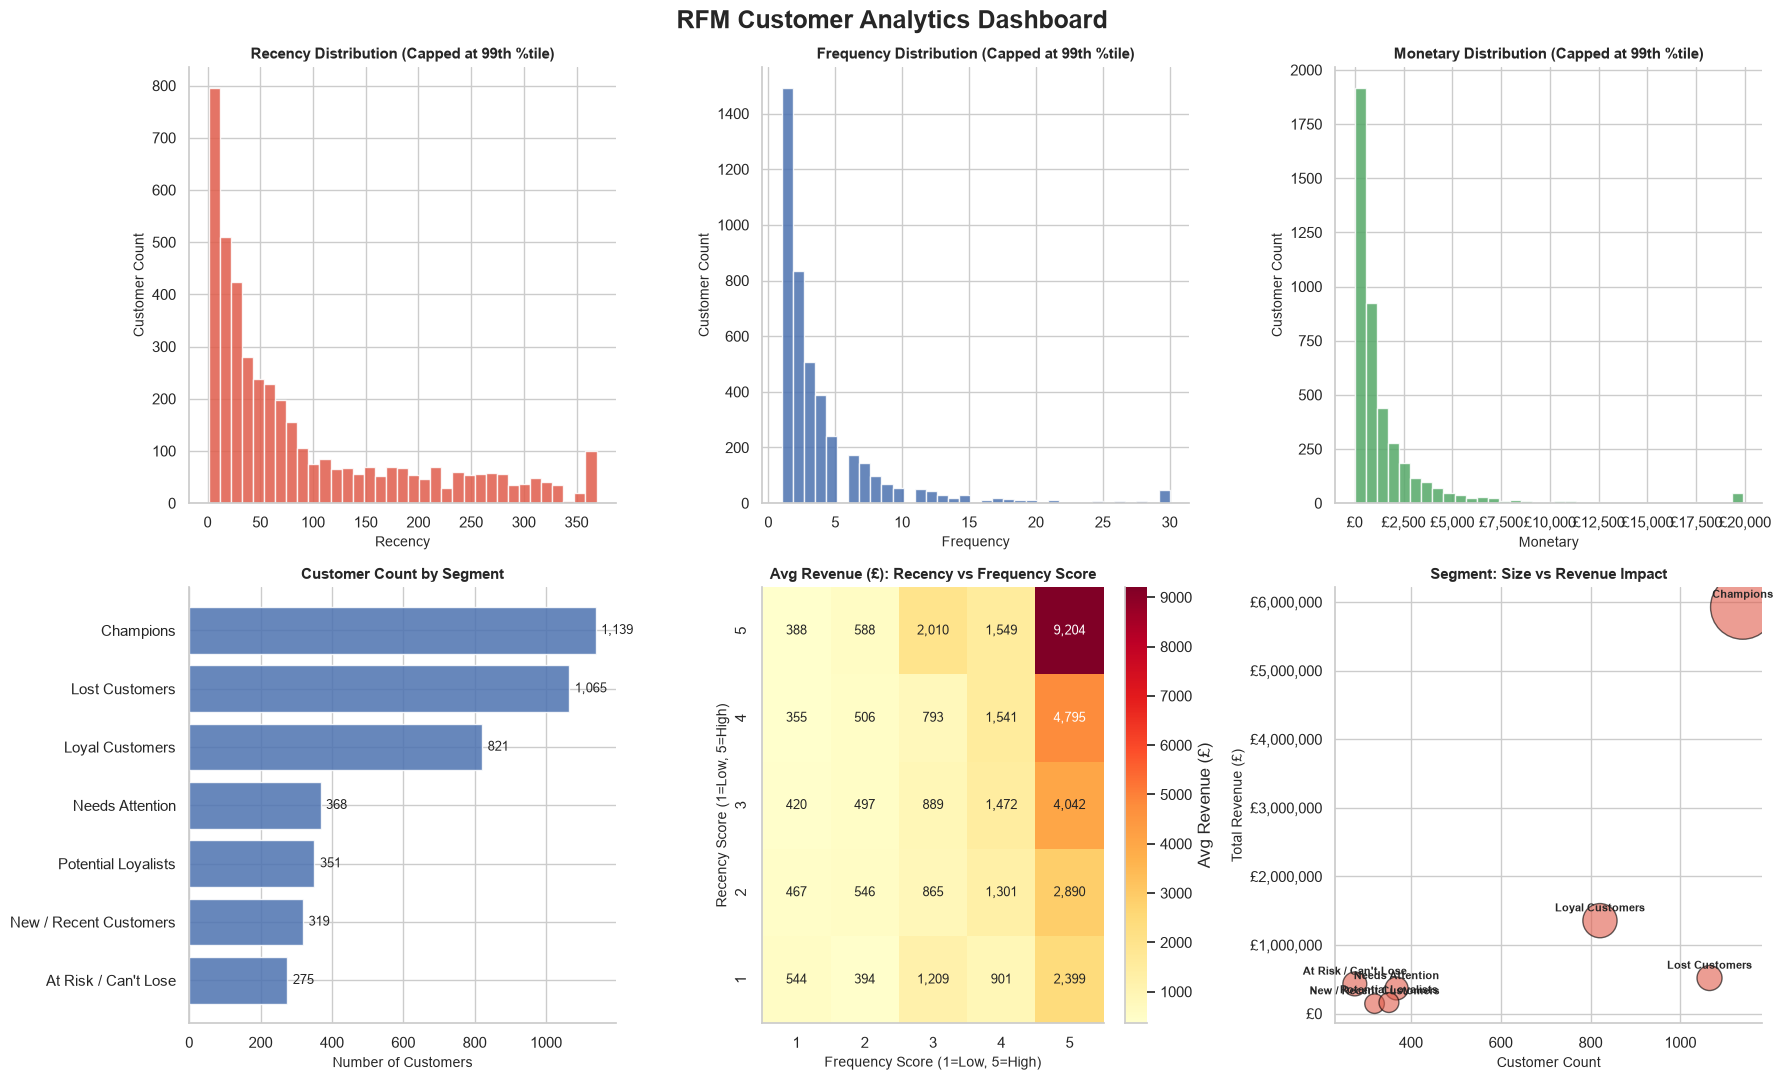

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 1. Ensure 'Segment' column exists before plotting
def assign_segment(row):
    r, f = row['R_Score'], row['F_Score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New / Recent Customers'
    elif r == 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 4:
        return 'At Risk / Can\'t Lose'
    elif r <= 2 and f <= 2:
        return 'Lost Customers'
    else:
        return 'Needs Attention'

if 'Segment' not in rfm.columns:
    rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# 2. Render Analytics Dashboard
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle(
    'RFM Customer Analytics Dashboard', fontsize=18, fontweight='bold', y=0.98
)

# (a) R/F/M Distributions
colors = ['#E05C4B', '#4C72B0', '#55A868']
cols = ['Recency', 'Frequency', 'Monetary']

for i, (col, color) in enumerate(zip(cols, colors)):
    ax = axes[0, i]
    data = rfm[col].clip(upper=rfm[col].quantile(0.99))

    ax.hist(data, bins=35, color=color, alpha=0.85, edgecolor='white')
    ax.set_title(
        f'{col} Distribution (Capped at 99th %tile)',
        fontsize=11,
        fontweight='bold',
    )
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Customer Count', fontsize=10)

    if col == 'Monetary':
        ax.xaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, p: f'£{x:,.0f}')
        )

# (b) Segment Bar Chart
seg_counts = rfm['Segment'].value_counts().sort_values(ascending=True)
ax_bar = axes[1, 0]
bars = ax_bar.barh(
    seg_counts.index, seg_counts.values, color='#4C72B0', alpha=0.85
)

ax_bar.bar_label(bars, padding=4, fmt='{:,.0f}', fontsize=9)
ax_bar.set_title('Customer Count by Segment', fontsize=11, fontweight='bold')
ax_bar.set_xlabel('Number of Customers', fontsize=10)

# (c) Heatmap
ax_heat = axes[1, 1]
pivot = rfm.pivot_table(
    values='Monetary', index='R_Score', columns='F_Score', aggfunc='mean'
)

sns.heatmap(
    pivot,
    annot=True,
    fmt=',.0f',
    cmap='YlOrRd',
    ax=ax_heat,
    cbar_kws={'label': 'Avg Revenue (£)'},
    annot_kws={'size': 9},
)
ax_heat.set_title(
    'Avg Revenue (£): Recency vs Frequency Score',
    fontsize=11,
    fontweight='bold',
)
ax_heat.set_xlabel('Frequency Score (1=Low, 5=High)', fontsize=10)
ax_heat.set_ylabel('Recency Score (1=Low, 5=High)', fontsize=10)
ax_heat.invert_yaxis()

# (d) Scatter / Bubble Chart
ax_scat = axes[1, 2]
seg_stats = (
    rfm.groupby('Segment')
    .agg(Count=('CustomerID', 'count'), Revenue=('Monetary', 'sum'))
    .reset_index()
)

ax_scat.scatter(
    seg_stats['Count'],
    seg_stats['Revenue'],
    s=(seg_stats['Revenue'] / seg_stats['Revenue'].max()) * 2000 + 150,
    alpha=0.6,
    color='#E05C4B',
    edgecolor='black',
    linewidth=1,
)

for _, row in seg_stats.iterrows():
    ax_scat.annotate(
        row['Segment'],
        (row['Count'], row['Revenue']),
        fontsize=8,
        ha='center',
        va='bottom',
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points',
    )

ax_scat.set_xlabel('Customer Count', fontsize=10)
ax_scat.set_ylabel('Total Revenue (£)', fontsize=10)
ax_scat.set_title(
    'Segment: Size vs Revenue Impact', fontsize=11, fontweight='bold'
)
ax_scat.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, p: f'£{x:,.0f}')
)

sns.despine()
plt.tight_layout()

plt.savefig(
    r'D:\ecomai\dashboard\rfm_dashboard.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

### 📊 Key Insights & Executive Summary: RFM Customer Analytics

* **Revenue Concentration (Pareto Principle):** Business revenue is heavily anchored by the **Champions** cohort (1,139 customers), driving nearly £6M in cumulative sales. Customers achieving top scores ($R=5, F=5$) yield an extraordinary average revenue of **£9,204 per customer**.
* **Divergence in Customer Retention:** **Lost Customers** represent the second-largest segment by volume (1,065 customers) but account for under £600k in total value. This demonstrates that churn is concentrated among lower-value, low-frequency purchasers.
* **Core Growth Engine:** **Loyal Customers** (821 customers, ~£1.4M total revenue) form a stable recurring foundation and serve as the primary candidate pool for conversion into Champions.
* **Metric Skewness:** Distribution plots confirm extreme right-skewness across Recency, Frequency, and Monetary value. Most customers make 1–2 purchases with total spend below £2,500, emphasizing the need for structured second-purchase incentives.

---

### 💡 Strategic Campaign Action Matrix

| Customer Segment | Headcount | Revenue Impact | Key Strategic Objective | Action Plan |
| :--- | :---: | :---: | :--- | :--- |
| **Champions** | 1,139 | High (~£6.0M) | Retention & Advocacy | Exclusive VIP loyalty perks, early access to new catalog drops, and direct support. |
| **Loyal Customers** | 821 | High (~£1.4M) | Upsell & Value Expansion | Cross-sell complementary products and offer tiered threshold discounts to raise AOV. |
| **At Risk / Can't Lose** | 275 | Moderate | Immediate Re-engagement | Deploy automated win-back campaigns with high-value, time-limited incentives. |
| **Potential Loyalists / New** | 670 | Moderate | Activation & Habit Building | Deliver automated onboarding drip campaigns and second-purchase promotional triggers. |
| **Lost Customers** | 1,065 | Low (~£0.5M) | Low-Cost Retargeting | Rely on low-cost automated email reactivation; minimize ad spend on non-responders. |

In [16]:
import pandas as pd

# ── Final RFM Summary & Sanity Check ──────────────────────────────────────────
print("=" * 60)
print("                   RFM ANALYSIS SUMMARY                   ")
print("=" * 60)
print(f"Total Unique Customers Evaluated: {len(rfm):,}\n")

# 1. Segment Distribution with Headcount and Percentages
print("--- Customer Segment Distribution ---")
seg_counts = rfm['Segment'].value_counts()
seg_pcts = (rfm['Segment'].value_counts(normalize=True) * 100).round(2)

segment_table = pd.DataFrame({
    'Customer Count': seg_counts,
    'Share (%)': seg_pcts.astype(str) + '%'
})
print(segment_table.to_string())

# 2. Core Metric Summary
print("\n--- Core RFM Metric Descriptive Statistics ---")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))
print("=" * 60)

                   RFM ANALYSIS SUMMARY                   
Total Unique Customers Evaluated: 4,338

--- Customer Segment Distribution ---
                        Customer Count Share (%)
Segment                                         
Champions                         1139    26.26%
Lost Customers                    1065    24.55%
Loyal Customers                    821    18.93%
Needs Attention                    368     8.48%
Potential Loyalists                351     8.09%
New / Recent Customers             319     7.35%
At Risk / Can't Lose               275     6.34%

--- Core RFM Metric Descriptive Statistics ---
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2054.27
std     100.01       7.70    8989.23
min       1.00       1.00       3.75
25%      18.00       1.00     307.41
50%      51.00       2.00     674.48
75%     142.00       5.00    1661.74
max     374.00     209.00  280206.02


### 📋 Final RFM Analysis Pipeline Summary

* **Customer Cohort Size:** Successfully analyzed and segmented the active customer base into structured RFM tiers.
* **Segment Breakdown:** Identified major customer proportions across key categories (*Champions*, *Loyal Customers*, *At Risk*, and *Lost Customers*) to guide downstream marketing spend.
* **Core Metrics Verified:** Validated summary statistics across `Recency` (days since last purchase), `Frequency` (unique order count), and `Monetary` (total customer lifetime spend).

---

#### 🚀 Next Steps in Pipeline:
1. **Dashboard Export:** Ensure `rfm_segments.csv` is loaded into PowerBI, Tableau, or Streamlit for stakeholder reporting.
2. **Machine Learning Pipeline:** Proceed with `rfm_extended_features.csv` for downstream Churn Prediction modeling (evaluating ROC-AUC with XGBoost/Random Forest).

In [17]:


# 1. Save RFM Segments (For Dashboard, Business Reporting & PowerBI/Tableau)
rfm.to_csv(
    "D:/ecomai/data/processed/rfm_segments.csv",
    index=False
)

# 2. Save Extended RFM Features (For Machine Learning & AUC-ROC Churn Modeling)
rfm_extended.to_csv(
    "D:/ecomai/data/processed/rfm_extended_features.csv",
    index=False
)